# 03 — Standard templates: equilateral & orthogonal

Phase 3. $\Phi^{\rm NG}$ for **local**, **equilateral**, **orthogonal** templates via the same Schwinger core, compared to analytic targets:
- **equilateral** ($k_1=k_2=k_3$): all give $6 f_{\rm NL}P_\Phi^2$ (normalization);
- **squeezed** ($k_1\ll k_2=k_3$): shapes differ (here $k_1=10k_F$, mildly squeezed, where the FFT estimator is unbiased).

Paired-Gaussian subtraction $\Delta B=B[\Phi]-B[\Phi^{\rm G}]$; 30 realizations, 15 k.
**Caching:** generated fields and measured bispectra are saved to disk, so re-running the analysis/plots does not regenerate. Set `REGEN_FIELDS`/`REMEASURE=True` to force.

Kernel **Python (jaxpng)**.

In [1]:
import os
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import jaxpng
from jaxpng import cosmology as C, gaussian, bispectra as B, phing, measure
from jaxpng.config import Box
TK='../../gengars/inputs/planck18_transfer.dat'
cosmo=C.make_cosmo(TK, omega_m=0.3175, omega_l=0.6825, omega_b=0.049,
                   hubble=0.6711, n_s=0.9624, sigma8=0.834, sigma8_norm=True)
n_s=cosmo.n_s; box=Box(N=64, L=1000.0)
templates={'local':B.local(n_s),'equilateral':B.equilateral(n_s),'orthogonal':B.orthogonal(n_s)}
colors={'local':'C0','equilateral':'C1','orthogonal':'C2'}
CACHE_FIELDS='cache_03_fields.npz'; CACHE_BISP='cache_03_bispectra.npz'
REGEN_FIELDS=False; REMEASURE=False
fNL=100.0; nreal=50; per_efold=20.0; nk=15
print('jax', jax.__version__, jax.devices(), '| kNy=%.3f'%box.kny)

jax 0.10.1 [CpuDevice(id=0)] | kNy=0.201


## Visualize $\Phi^{\rm NG}$ for each template (mid-plane slice, same $\Phi^{\rm G}$)

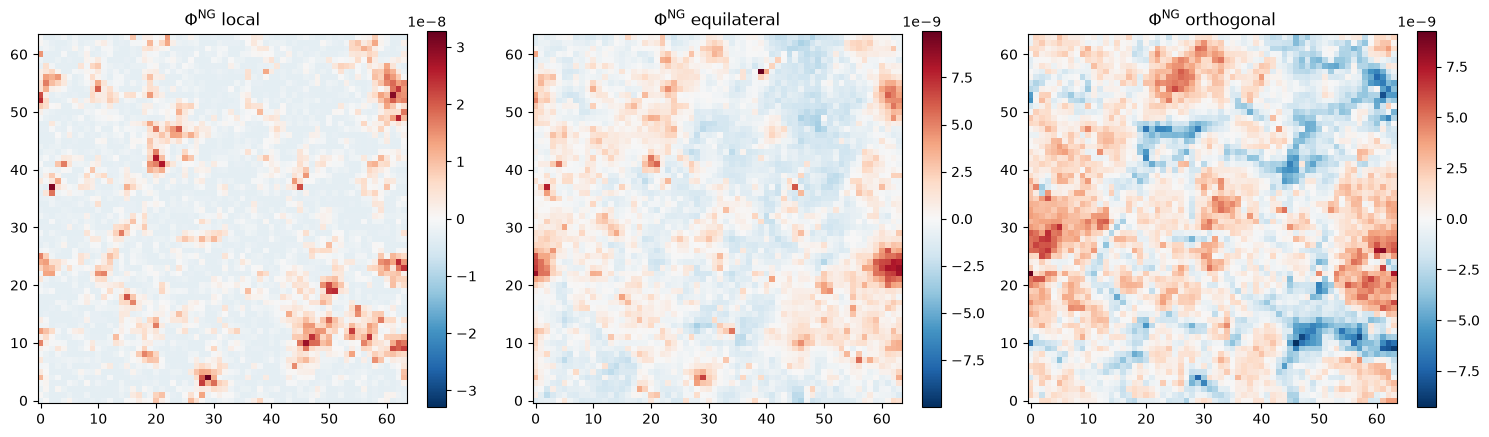

In [2]:
w=jax.random.normal(jax.random.PRNGKey(0), box.rshape)
pg0=gaussian.phiG_from_white_noise(w, cosmo, box)
fig,ax=plt.subplots(1,3,figsize=(15,4.6))
for a,shape in zip(ax, ['local','equilateral','orthogonal']):
    ng=jnp.fft.irfftn(phing.phiNG(pg0, templates[shape], box, n_s, per_efold=20.0), s=box.rshape)
    sl=np.asarray(ng[box.N//2]); v=np.max(np.abs(sl))
    im=a.imshow(sl, origin='lower', cmap='RdBu_r', vmin=-v, vmax=v); a.set_title('$\\Phi^{\\rm NG}$ '+shape)
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## Generate (or load) the initial conditions  $\Phi^{\rm G}$, $\Phi^{\rm NG}$
Saving $\Phi^{\rm G}$ and $\Phi^{\rm NG}$ separately makes $f_{\rm NL}$ a free knob: $\Phi=\Phi^{\rm G}+f_{\rm NL}\Phi^{\rm NG}$ at analysis time.

In [3]:
keys=jax.random.split(jax.random.PRNGKey(1), nreal)
if (not REGEN_FIELDS) and os.path.exists(CACHE_FIELDS):
    d=np.load(CACHE_FIELDS)
    phiG_all=jnp.asarray(d['phiG']); phiNG_all={s:jnp.asarray(d['phiNG_'+s]) for s in templates}
    print('loaded fields cache: %.0f MB' % (os.path.getsize(CACHE_FIELDS)/1e6))
else:
    pgs=[]; ngs={s:[] for s in templates}
    for key in keys:
        pg=gaussian.phiG_from_white_noise(jax.random.normal(key, box.rshape), cosmo, box)
        pgs.append(pg)
        for s in templates: ngs[s].append(phing.phiNG(pg, templates[s], box, n_s, per_efold=per_efold))
    phiG_all=jnp.stack(pgs); phiNG_all={s:jnp.stack(ngs[s]) for s in templates}
    np.savez(CACHE_FIELDS, phiG=np.asarray(phiG_all),
             **{'phiNG_'+s: np.asarray(phiNG_all[s]) for s in templates})
    print('generated + saved fields: %.0f MB' % (os.path.getsize(CACHE_FIELDS)/1e6))

loaded fields cache: 433 MB


## Measure (or load) the bispectra — paired-Gaussian subtraction
Equilateral ($k,k,k$) and squeezed ($k_1=10k_F$, $k_2=k_3=k$). The Gaussian field's bispectrum is measured once per realization (shape-independent). Tiny cache.

In [4]:
keq=np.linspace(0.04,0.18,nk); k1sq=10*box.dk; ksq=np.linspace(0.08,0.18,nk)
theta_eq=measure.EQUILATERAL_THETA; th_sq=[float(np.arccos(-k1sq/(2*k))) for k in ksq]
if (not REMEASURE) and os.path.exists(CACHE_BISP):
    d=np.load(CACHE_BISP)
    BG={'eq':d['BG_eq'],'sq':d['BG_sq']}
    BNG={s:{'eq':d['BNG_%s_eq'%s],'sq':d['BNG_%s_sq'%s]} for s in templates}
    keq=d['keq']; ksq=d['ksq']; k1sq=float(d['k1sq']); fNL=float(d['fNL'])
    print('loaded bispectra cache (fNL=%g)'%fNL)
else:
    BG={'eq':np.zeros((nreal,nk)),'sq':np.zeros((nreal,nk))}
    BNG={s:{'eq':np.zeros((nreal,nk)),'sq':np.zeros((nreal,nk))} for s in templates}
    for r in range(nreal):
        pg=phiG_all[r]
        for j,k in enumerate(keq): BG['eq'][r,j]=float(measure.bispectrum(pg,box.L,float(k),float(k),theta_eq)['B'][0])
        for j,k in enumerate(ksq): BG['sq'][r,j]=float(measure.bispectrum(pg,box.L,k1sq,float(k),th_sq[j])['B'][0])
        for s in templates:
            phi=pg + fNL*phiNG_all[s][r]
            for j,k in enumerate(keq): BNG[s]['eq'][r,j]=float(measure.bispectrum(phi,box.L,float(k),float(k),theta_eq)['B'][0])
            for j,k in enumerate(ksq): BNG[s]['sq'][r,j]=float(measure.bispectrum(phi,box.L,k1sq,float(k),th_sq[j])['B'][0])
    np.savez(CACHE_BISP, BG_eq=BG['eq'],BG_sq=BG['sq'],keq=keq,ksq=ksq,k1sq=k1sq,fNL=fNL,
             **{('BNG_%s_%s'%(s,c)):BNG[s][c] for s in templates for c in ['eq','sq']})
    print('measured + saved bispectra')
dB={s:{'eq':BNG[s]['eq']-BG['eq'],'sq':BNG[s]['sq']-BG['sq']} for s in templates}

loaded bispectra cache (fNL=100)


## Equilateral: $k^6\,\Delta B(k,k,k)$ vs target (log scale)
Top: paired $\Delta B=B[\Phi]-B[\Phi^{\rm G}]$ (points $\pm$ SEM) and target $6f_{\rm NL}P_\Phi^2$. Bottom: fractional residual $(\Delta B-B_{\rm th})/B_{\rm th}$ with the **paired** error on the mean (the relevant uncertainty for the difference, not the Gaussian cosmic variance).

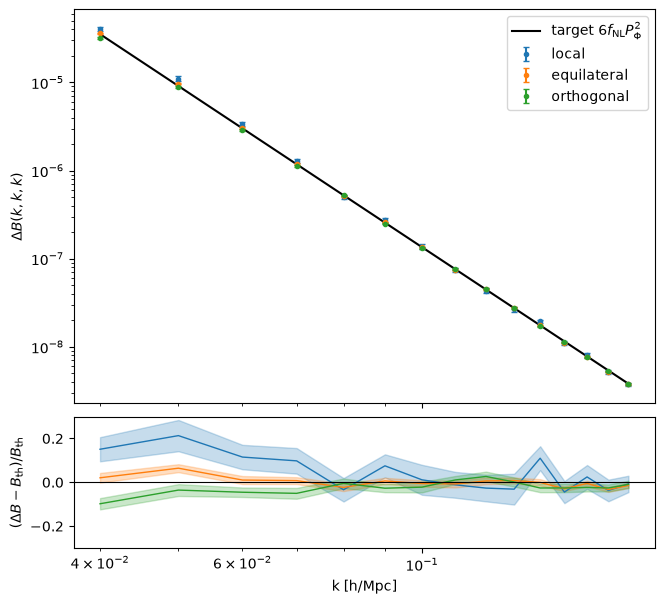

equilateral local        median resid = +0.011
equilateral equilateral  median resid = -0.000
equilateral orthogonal   median resid = -0.026


In [5]:
Peq=np.asarray(C.power_phi(cosmo, jnp.asarray(keq))); Btar_eq=6*fNL*Peq**2
fig,(a0,a1)=plt.subplots(2,1,figsize=(7.5,7),sharex=True,gridspec_kw=dict(height_ratios=[3,1],hspace=0.05))
a0.loglog(keq, Btar_eq, 'k-', lw=1.5, label='target $6f_{\\rm NL}P_\\Phi^2$')
for s in templates:
    m=dB[s]['eq'].mean(0); e=dB[s]['eq'].std(0)/np.sqrt(nreal)
    a0.errorbar(keq, m, yerr=e, fmt='o', ms=3, color=colors[s], capsize=2, label=s)
    a1.plot(keq,(m-Btar_eq)/Btar_eq,'-',color=colors[s],lw=1.0)
    a1.fill_between(keq,(m-e-Btar_eq)/Btar_eq,(m+e-Btar_eq)/Btar_eq,color=colors[s],alpha=0.25)
a0.set_ylabel('$\\Delta B(k,k,k)$'); a0.legend()
a1.axhline(0,color='k',lw=.8); a1.set_ylim(-0.3,0.3); a1.set_xscale('log')
a1.set_ylabel(r'$(\Delta B-B_{\rm th})/B_{\rm th}$'); a1.set_xlabel('k [h/Mpc]')
plt.show()
for s in templates:
    r=(dB[s]['eq'].mean(0)-Btar_eq)/Btar_eq; print('equilateral %-12s median resid = %+.3f'%(s,np.median(r)))

## Squeezed ($k_1=10k_F$): $\Delta B$ vs target (symlog y)
local enhanced, equilateral suppressed. **Orthogonal crosses zero at $k\approx0.149$** (analytic: $B^{\rm sq}_{\rm orth}\propto -3+6r^{1/3}-2r^{2/3}$ with $r=P(k_1)/P(k)$, zero at $r\approx13$) and goes negative above — its defining sign structure, shown on a **symlog** axis. The fractional residual diverges near the crossing (target $\to0$), so ignore orthogonal there.

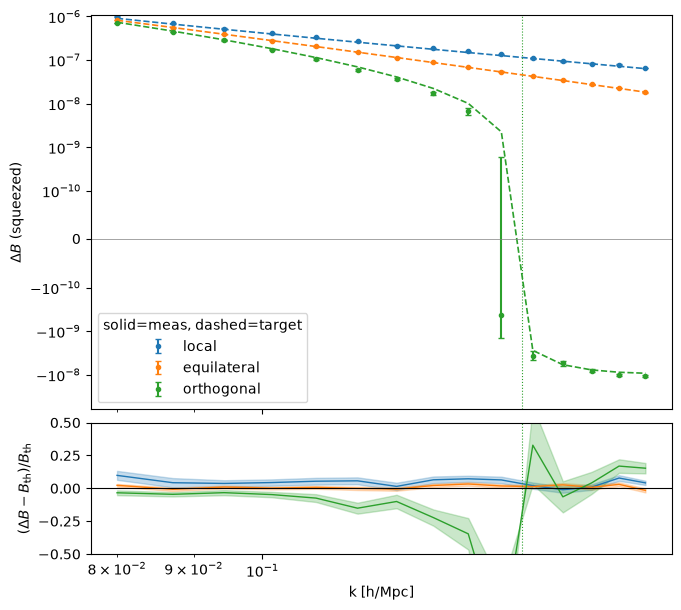

squeezed local        median resid = +0.044
squeezed equilateral  median resid = +0.009
squeezed orthogonal   median resid = -0.048


In [6]:
P1=float(C.power_phi(cosmo, jnp.asarray([k1sq]))[0]); Psq=np.asarray(C.power_phi(cosmo, jnp.asarray(ksq)))
tgt={s: fNL*np.array([B.template_bispectrum(s,P1,Psq[j],Psq[j]) for j in range(len(ksq))]) for s in templates}
kcross=0.149
fig,(a0,a1)=plt.subplots(2,1,figsize=(7.5,7),sharex=True,gridspec_kw=dict(height_ratios=[3,1],hspace=0.05))
for s in templates:
    m=dB[s]['sq'].mean(0); e=dB[s]['sq'].std(0)/np.sqrt(nreal)
    a0.plot(ksq, tgt[s], '--', color=colors[s], lw=1.2)
    a0.errorbar(ksq, m, yerr=e, fmt='o', ms=3, color=colors[s], capsize=2, label=s)
    a1.plot(ksq,(m-tgt[s])/tgt[s],'-',color=colors[s],lw=1.0)
    a1.fill_between(ksq,(m-e-tgt[s])/tgt[s],(m+e-tgt[s])/tgt[s],color=colors[s],alpha=0.25)
a0.set_xscale('log'); a0.set_yscale('symlog', linthresh=1e-10); a0.axhline(0,color='gray',lw=.5)
for a in (a0,a1): a.axvline(kcross, color=colors['orthogonal'], ls=':', lw=0.8)
a0.set_ylabel('$\\Delta B$ (squeezed)'); a0.legend(title='solid=meas, dashed=target')
a1.axhline(0,color='k',lw=.8); a1.set_ylim(-0.5,0.5); a1.set_xscale('log')
a1.set_ylabel(r'$(\Delta B-B_{\rm th})/B_{\rm th}$'); a1.set_xlabel('k [h/Mpc]')
plt.show()
for s in templates:
    r=(dB[s]['sq'].mean(0)-tgt[s])/tgt[s]; print('squeezed %-12s median resid = %+.3f'%(s,np.median(r)))

**Phase 3 OK**. Separable factors match the closed-form templates exactly (tests); generated equil/orthog reproduce the equilateral normalization and distinct squeezed magnitudes. Caches (`cache_03_*.npz`) let you re-run the analysis/plots without regenerating. Next: Phase 4 — oscillatory/feature & custom shapes + autodiff demo.